# Forecast Using ci-proto


In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot,ci-proto]"


foundationforecast ships a `CIProto` class for [Continuous Intelligence](https://github.com/continuousintelligence/ci)'s [ci-proto](https://huggingface.co/ContinuousIntelligence/ci-proto) model.

| Checkpoint | `repo_id` | Parameters | Native quantiles |
|------------|-----------|------------|------------------|
| **ci-proto** (default) | `ContinuousIntelligence/ci-proto` | ~167M | 0.1–0.9 |

Install the optional extra first: `pip install "foundationforecast[ci-proto]"` (this notebook uses `foundationforecast[plot,ci-proto]`).

**Highlights:**

- Very long context (16k steps on the standard checkpoint; longer histories switch to the long checkpoint automatically).
- Native prediction intervals: pass `level` or `quantiles` without conformal calibration.
- Known-future covariates via `X_df` when you have exogenous variables for the horizon.

Weights are released under the [ci-proto Code and Model Licence](https://github.com/continuousintelligence/ci/blob/main/LICENCE). Uses ci-proto, released by Continuous Intelligence. Continuous Intelligence does not endorse or approve this product or service. A CUDA GPU is recommended; CPU works through the portable backend.


## Import libraries


In [2]:
import pandas as pd

from foundationforecast import FoundationForecast
from foundationforecast.models import CIProto


/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:datasets:JAX version 0.12.0.1 available.


## Load the dataset

The DataFrame must include at least:

- `unique_id`: series identifier
- `ds`: timestamps
- `y`: target values

We use a small slice of M4 Hourly (first eight series) so the notebook runs in reasonable time.


In [3]:
df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/m4-hourly.parquet"
)
df = df[df["unique_id"].isin(df["unique_id"].unique()[:8])]
df.head()


,unique_id,ds,y
0,H1,2000-01-01 00:00:00,605.0
1,H1,2000-01-01 01:00:00,586.0
2,H1,2000-01-01 02:00:00,586.0
3,H1,2000-01-01 03:00:00,559.0
4,H1,2000-01-01 04:00:00,511.0


## Plot the data


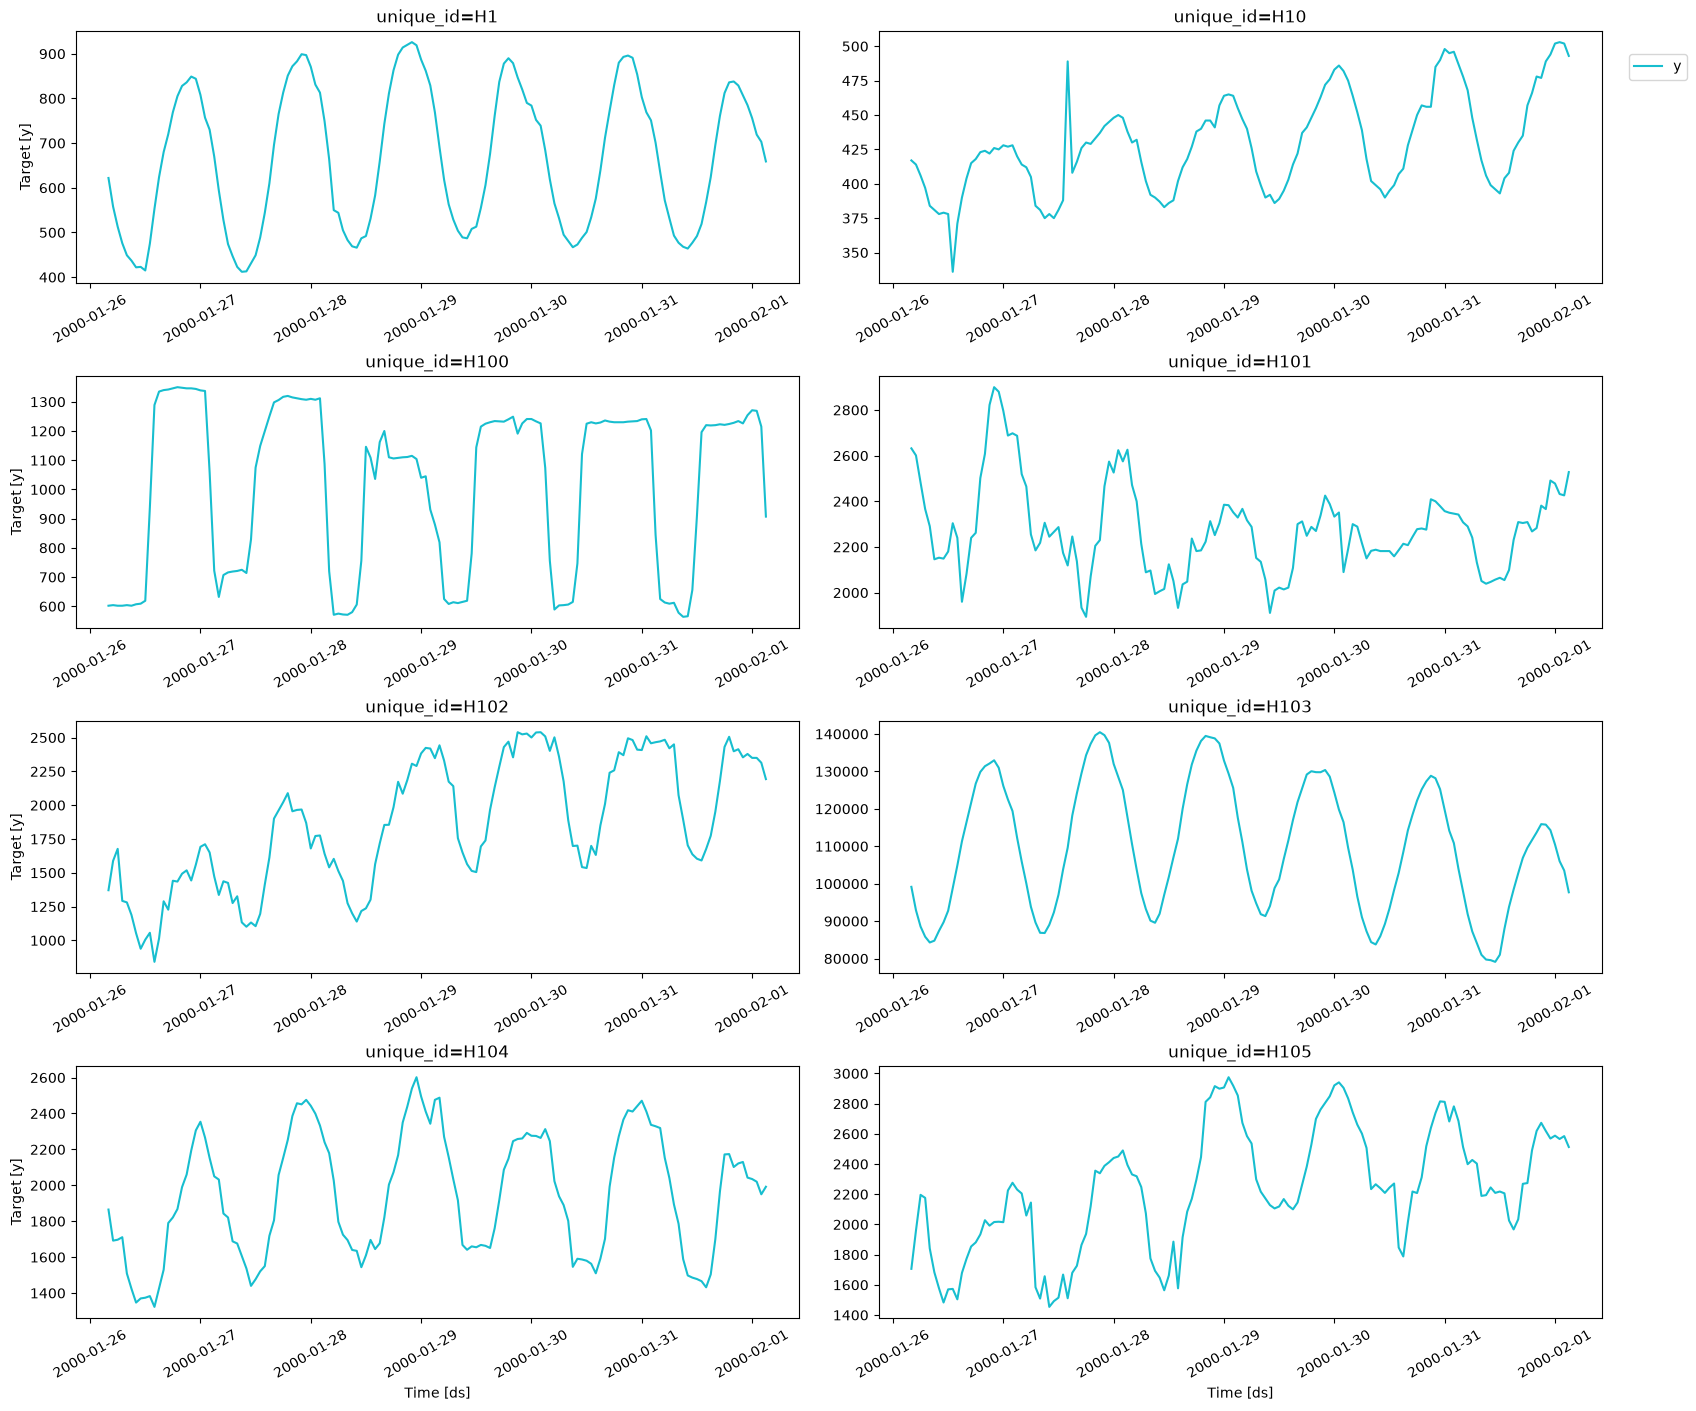

In [4]:
FoundationForecast.plot(df, max_insample_length=48 * 3, plot_random=False)


## Create a FoundationForecast


In [5]:
models = [CIProto(context_length=512)]

ff = FoundationForecast(models=models)


## Generate forecast

`CIProto` returns the median in the model column and native quantile bands for `level`/`quantiles`.


In [6]:
h = 48
level = [80, 95]
fcst_df = ff.forecast(df=df, h=h, level=level)
fcst_df.head()


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Fetching 3 files:  33%|███▎      | 1/3 [00:00<00:00,  2.66it/s]

Fetching 3 files:  67%|██████▋   | 2/3 [00:07<00:04,  4.13s/it]

Fetching 3 files: 100%|██████████| 3/3 [00:07<00:00,  2.56s/it]

Fetching 3 files: 100%|██████████| 3/3 [00:07<00:00,  2.61s/it]

2026-11-16 19:19:19  [TileLang:tilelang.jit.kernel:INFO]: TileLang begins to compile kernel `mamba_mimo_fwd_kernel` with `out_idx=[]`


2026-11-16 19:19:35  [TileLang:tilelang.jit.kernel:INFO]: TileLang completes to compile kernel `mamba_mimo_fwd_kernel`


/usr/local/lib/python3.12/site-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = c10::BFloat16, weight dtype = float, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)
  return torch.rms_norm(input, normalized_shape, weight, eps)


,unique_id,ds,CIProto,CIProto-lo-80,CIProto-hi-80,CIProto-lo-95,CIProto-hi-95
0,H1,2000-02-01 04:00:00,606.0,596.0,617.0,596.0,617.0
1,H1,2000-02-01 05:00:00,549.0,535.0,565.0,535.0,565.0
2,H1,2000-02-01 06:00:00,510.0,492.0,527.0,492.0,527.0
3,H1,2000-02-01 07:00:00,476.0,457.0,495.0,457.0,495.0
4,H1,2000-02-01 08:00:00,453.0,432.0,476.0,432.0,476.0


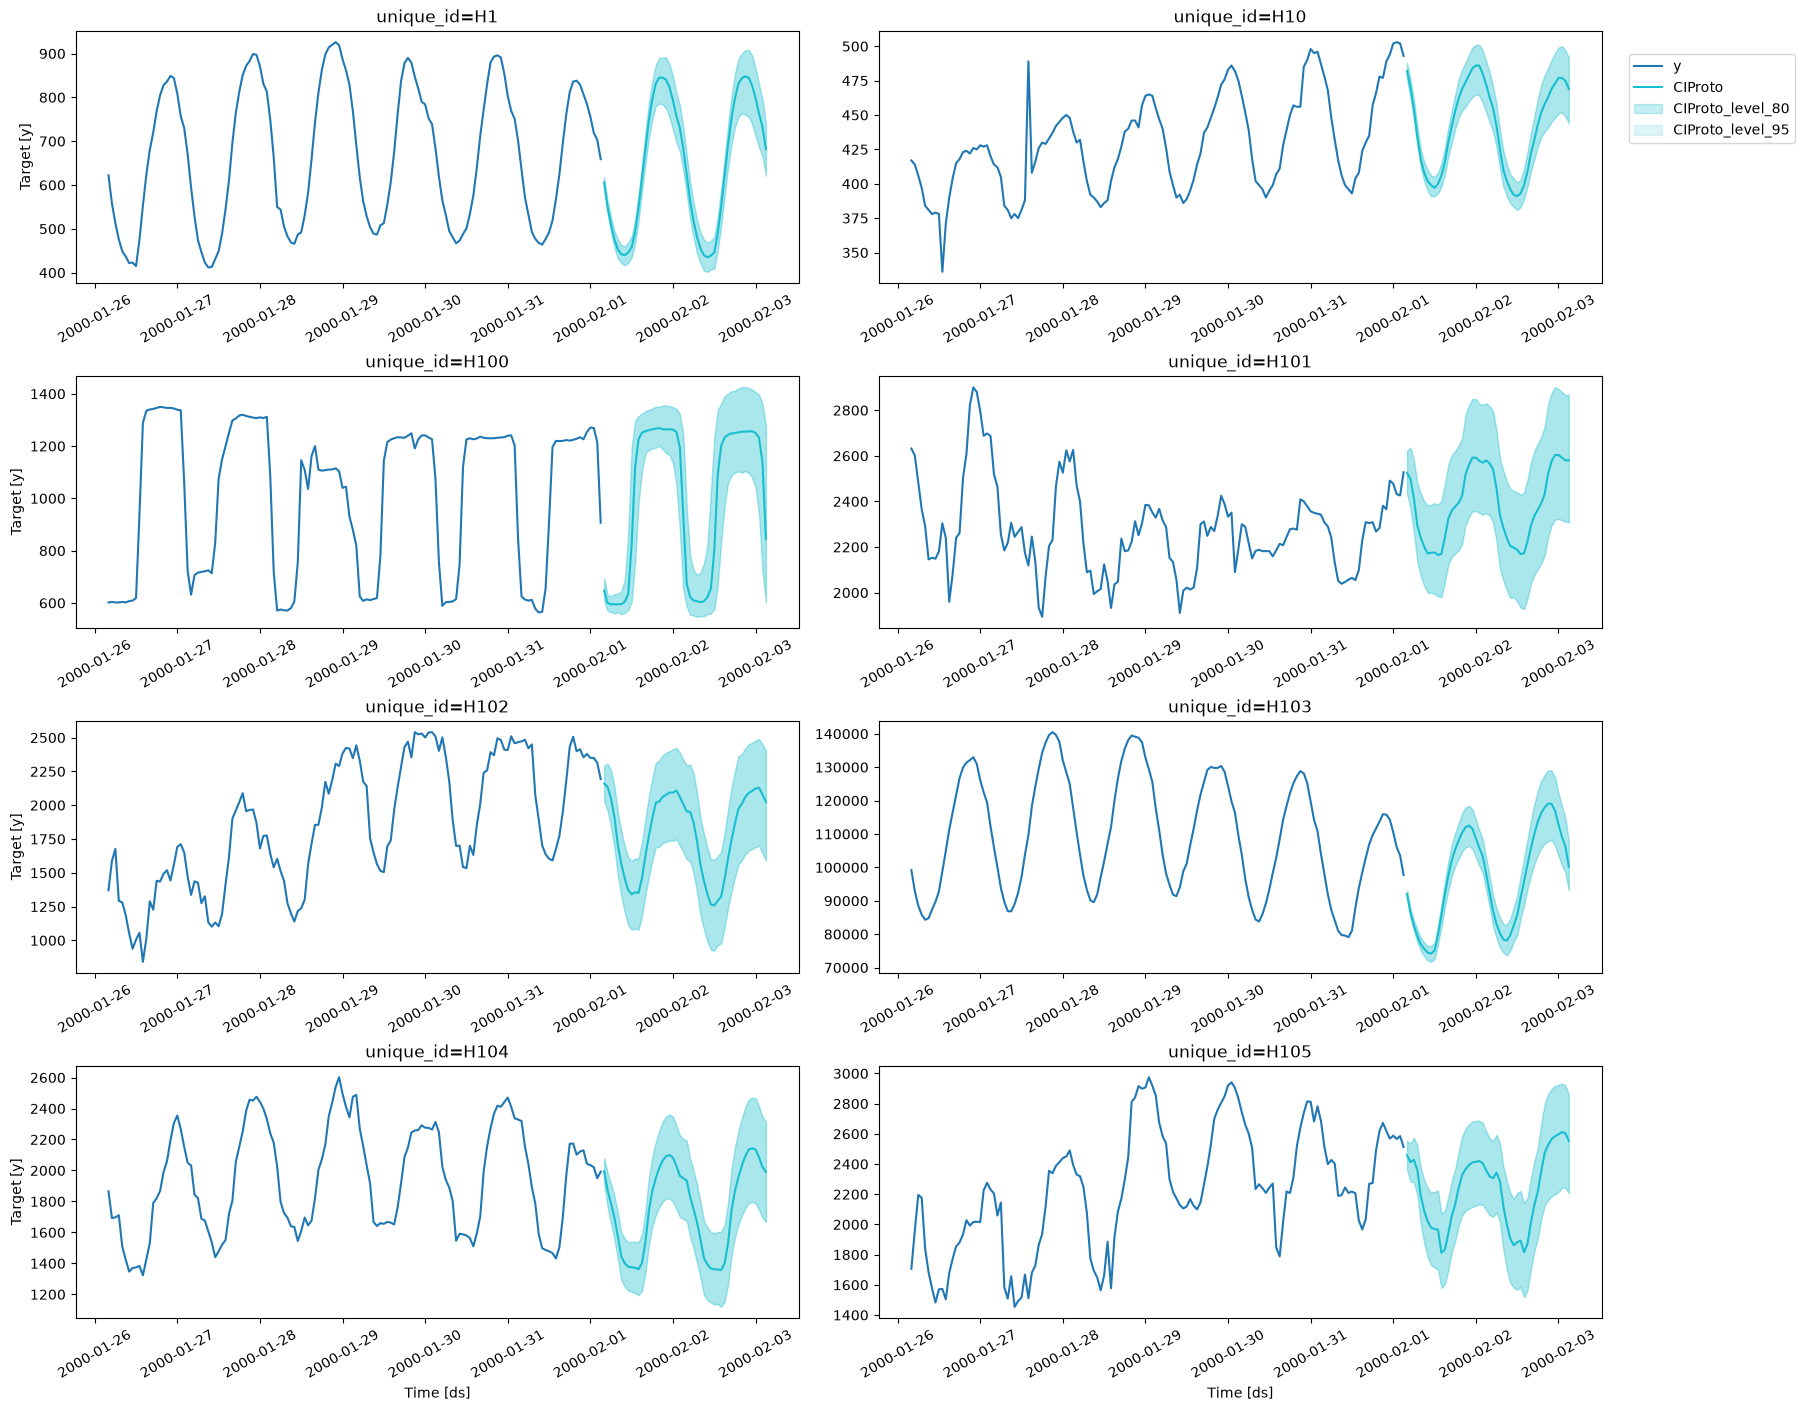

In [7]:
ff.plot(df, fcst_df, level=level, max_insample_length=48 * 3, plot_random=False)


## Known-future covariates

ci-proto reads `X_df` natively. Below we forecast German day-ahead electricity prices with market covariates (dataset from the TimeH2O example).


In [8]:
train = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/electricity_price/train.parquet"
)
x_future = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/electricity_price/futr_exog.parquet"
)
panel = train[train["unique_id"] == "DE"].sort_values("ds")
x_df = x_future[x_future["unique_id"] == "DE"].sort_values("ds")
h_epf = len(x_df)

ff_exog = FoundationForecast(models=[CIProto(alias="CIProto", context_length=512)])
fcst_epf = ff_exog.forecast(df=panel, h=h_epf, X_df=x_df, level=[80])
fcst_epf.head()


,unique_id,ds,CIProto,CIProto-lo-80,CIProto-hi-80
0,DE,2017-12-12 00:00:00,24.110428,19.847534,27.634823
1,DE,2017-12-12 01:00:00,20.910042,15.289671,25.688133
2,DE,2017-12-12 02:00:00,17.521858,11.350038,23.413162
3,DE,2017-12-12 03:00:00,16.025978,9.792737,22.901569
4,DE,2017-12-12 04:00:00,16.354465,9.649341,23.557840
